In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/store-sales-time-series-forecasting/oil.csv
/kaggle/input/competitions/store-sales-time-series-forecasting/sample_submission.csv
/kaggle/input/competitions/store-sales-time-series-forecasting/holidays_events.csv
/kaggle/input/competitions/store-sales-time-series-forecasting/stores.csv
/kaggle/input/competitions/store-sales-time-series-forecasting/train.csv
/kaggle/input/competitions/store-sales-time-series-forecasting/test.csv
/kaggle/input/competitions/store-sales-time-series-forecasting/transactions.csv


# 01. Dataset Loading & Structure Analysis

In this section, we will load all competition datasets and explore their basic structure, dimensions, and data types.

In [2]:
import pandas as pd
import numpy as np

DATA_DIR = "/kaggle/input/competitions/store-sales-time-series-forecasting/"

# Load datasets
train = pd.read_csv(DATA_DIR + "train.csv")
test = pd.read_csv(DATA_DIR + "test.csv")
stores = pd.read_csv(DATA_DIR + "stores.csv")
oil = pd.read_csv(DATA_DIR + "oil.csv")
holidays = pd.read_csv(DATA_DIR + "holidays_events.csv")
transactions = pd.read_csv(DATA_DIR + "transactions.csv")
sample_submission = pd.read_csv(DATA_DIR + "sample_submission.csv")

print("All datasets loaded successfully!")

All datasets loaded successfully!


## 2. Dataset Overview

In this step, we examined the dimensions of all provided datasets to understand their sizes and get an initial overview of the available data.

In [3]:
datasets = {
    "Train": train,
    "Test" : test,
    "Stores" : stores,
    "Oil" : oil,
    "Holidays" : holidays,
    "Transactions" : transactions,
    "Sample Submission": sample_submission
}

for name, df in datasets.items():
    print(f"{name}: {df.shape}")

Train: (3000888, 6)
Test: (28512, 5)
Stores: (54, 5)
Oil: (1218, 2)
Holidays: (350, 6)
Transactions: (83488, 3)
Sample Submission: (28512, 2)


## 3. Columns and Data Types

In this step, we inspected the columns and data types of each dataset to understand the available features and identify potential preprocessing requirements.

In [4]:
for name, df in datasets.items():

    print(f"\n{'='*50}")
    print(f"Dataset: {name}")
    print(f"{'='*50}")

    print("\nColumns:")
    print(df.columns.tolist())

    print("\nData Types:")
    print(df.dtypes)


Dataset: Train

Columns:
['id', 'date', 'store_nbr', 'family', 'sales', 'onpromotion']

Data Types:
id               int64
date            object
store_nbr        int64
family          object
sales          float64
onpromotion      int64
dtype: object

Dataset: Test

Columns:
['id', 'date', 'store_nbr', 'family', 'onpromotion']

Data Types:
id              int64
date           object
store_nbr       int64
family         object
onpromotion     int64
dtype: object

Dataset: Stores

Columns:
['store_nbr', 'city', 'state', 'type', 'cluster']

Data Types:
store_nbr     int64
city         object
state        object
type         object
cluster       int64
dtype: object

Dataset: Oil

Columns:
['date', 'dcoilwtico']

Data Types:
date           object
dcoilwtico    float64
dtype: object

Dataset: Holidays

Columns:
['date', 'type', 'locale', 'locale_name', 'description', 'transferred']

Data Types:
date           object
type           object
locale         object
locale_name    object
descript

## 4. Unique Values Analysis

In this step, we examined the number of unique values in selected columns to identify potential keys and better understand the structure of each dataset.

In [5]:
key_candidates = {
    "Train": {
        "id": train,
        "store_nbr": train,
        "family": train,
        "date": train
    },
    "Stores": {
        "store_nbr": stores
    },
    "Oil": {
        "date": oil
    },
    "Holidays": {
        "date": holidays
    },
    "Transactions": {
        "store_nbr": transactions,
        "date": transactions
    }
}

for dataset_name, columns in key_candidates.items():

    print(f"\n{'='*40}")
    print(dataset_name)
    print(f"{'='*40}")

    for column, df in columns.items():
        print(
            f"{column}: "
            f"{df[column].nunique()} unique values "
            f"out of {len(df)} rows"
        )


Train
id: 3000888 unique values out of 3000888 rows
store_nbr: 54 unique values out of 3000888 rows
family: 33 unique values out of 3000888 rows
date: 1684 unique values out of 3000888 rows

Stores
store_nbr: 54 unique values out of 54 rows

Oil
date: 1218 unique values out of 1218 rows

Holidays
date: 312 unique values out of 350 rows

Transactions
store_nbr: 54 unique values out of 83488 rows
date: 1682 unique values out of 83488 rows


## 5. Missing Values Analysis

In this step, we investigated missing values across all datasets to identify incomplete data and determine which features may require further attention during preprocessing.

In [6]:
for name, df in datasets.items():

    print("\n" + "=" * 40)
    print(f"Missing Values - {name}")
    print("=" * 40)

    missing = df.isnull().sum()

    missing_percentage = (missing / len(df)) * 100

    missing_report = pd.DataFrame({
        "Missing Values": missing,
        "Percentage (%)": missing_percentage
    })

    print(missing_report)


Missing Values - Train
             Missing Values  Percentage (%)
id                        0             0.0
date                      0             0.0
store_nbr                 0             0.0
family                    0             0.0
sales                     0             0.0
onpromotion               0             0.0

Missing Values - Test
             Missing Values  Percentage (%)
id                        0             0.0
date                      0             0.0
store_nbr                 0             0.0
family                    0             0.0
onpromotion               0             0.0

Missing Values - Stores
           Missing Values  Percentage (%)
store_nbr               0             0.0
city                    0             0.0
state                   0             0.0
type                    0             0.0
cluster                 0             0.0

Missing Values - Oil
            Missing Values  Percentage (%)
date                     0        0.000

## 6. Duplicate Analysis

In this step, we checked all datasets for completely duplicated rows to identify potential data quality issues and ensure the reliability of the data.

In [7]:
for name, df in datasets.items():

    print(f"\n{'='*40}")
    print(f"Duplicate Analysis - {name}")
    print(f"{'='*40}")

    duplicates = df.duplicated().sum()

    print(f"Duplicate Rows: {duplicates}")
    print(f"Duplicate Percentage: {(duplicates / len(df)) * 100:.4f}%")


Duplicate Analysis - Train
Duplicate Rows: 0
Duplicate Percentage: 0.0000%

Duplicate Analysis - Test
Duplicate Rows: 0
Duplicate Percentage: 0.0000%

Duplicate Analysis - Stores
Duplicate Rows: 0
Duplicate Percentage: 0.0000%

Duplicate Analysis - Oil
Duplicate Rows: 0
Duplicate Percentage: 0.0000%

Duplicate Analysis - Holidays
Duplicate Rows: 0
Duplicate Percentage: 0.0000%

Duplicate Analysis - Transactions
Duplicate Rows: 0
Duplicate Percentage: 0.0000%

Duplicate Analysis - Sample Submission
Duplicate Rows: 0
Duplicate Percentage: 0.0000%


## 7. Date Range Analysis

In this step, we examined the date ranges of the main datasets to understand their temporal coverage and identify potential limitations when building forecasting features.


In [8]:
date_columns = {
    "Train": train,
    "Test": test,
    "Oil": oil,
    "Holidays": holidays,
    "Transactions": transactions
}

for name, df in date_columns.items():
    df["date"] = pd.to_datetime(df["date"])

    print(f"\n{'='*40}")
    print(f"Date Range - {name}")
    print(f"{'='*40}")

    print("Start Date:", df["date"].min())
    print("End Date:", df["date"].max())
    print("Unique Dates:", df["date"].nunique())


Date Range - Train
Start Date: 2013-01-01 00:00:00
End Date: 2017-08-15 00:00:00
Unique Dates: 1684

Date Range - Test
Start Date: 2017-08-16 00:00:00
End Date: 2017-08-31 00:00:00
Unique Dates: 16

Date Range - Oil
Start Date: 2013-01-01 00:00:00
End Date: 2017-08-31 00:00:00
Unique Dates: 1218

Date Range - Holidays
Start Date: 2012-03-02 00:00:00
End Date: 2017-12-26 00:00:00
Unique Dates: 312

Date Range - Transactions
Start Date: 2013-01-01 00:00:00
End Date: 2017-08-15 00:00:00
Unique Dates: 1682



### Date Range Summary

| Dataset | Start Date | End Date | Unique Dates |
|---|---|---|---:|
| Train | 2013-01-01 | 2017-08-15 | 1,684 |
| Test | 2017-08-16 | 2017-08-31 | 16 |
| Oil | 2013-01-01 | 2017-08-31 | 1,218 |
| Holidays | 2012-03-02 | 2017-12-26 | 312 |
| Transactions | 2013-01-01 | 2017-08-15 | 1,682 |

### Key Findings

1. **Training Period:** The training dataset covers approximately 4 years and 7 months, from January 1, 2013, to August 15, 2017.

2. **Testing Period:** The test dataset covers 16 days, from August 16 to August 31, 2017, immediately following the training period.

3. **Oil Data:** The oil dataset extends through the entire test period, making it a potentially useful feature for forecasting.

4. **Holidays Data:** The holidays dataset covers a wider period than both training and testing, allowing us to extract holiday-related features for the test period.

5. **Transactions Data:** The transactions dataset ends on August 15, 2017. Therefore, actual transaction values are unavailable for the test period and cannot be directly used as future inputs.

6. **Date Coverage:** The transactions dataset contains 1,682 unique dates, compared with 1,684 unique dates in the training dataset. The missing dates require further investigation.

### Important Considerations

- Investigate the missing dates in the transactions dataset.
- Handle missing oil prices carefully before feature engineering.
- Avoid using unavailable future information when constructing features.
- Consider extracting calendar and holiday-related features.

### Conclusion

The datasets provide sufficient historical coverage for time series forecasting. However, their different date ranges and availability must be considered carefully during feature engineering and model development.

## 8. Target Analysis

In this step, we analyzed the target variable (sales) to understand its distribution, identify unusual values, and gain insights into the sales patterns before building forecasting models.

In [9]:
print("Target Statistics:")
display(train["sales"].describe())

print("\nZero Sales:")
print((train["sales"] == 0).sum())

print("\nNegative Sales:")
print((train["sales"] < 0).sum())

print("\nPositive Sales:")
print((train["sales"] > 0).sum())

Target Statistics:


count    3.000888e+06
mean     3.577757e+02
std      1.101998e+03
min      0.000000e+00
25%      0.000000e+00
50%      1.100000e+01
75%      1.958473e+02
max      1.247170e+05
Name: sales, dtype: float64


Zero Sales:
939130

Negative Sales:
0

Positive Sales:
2061758


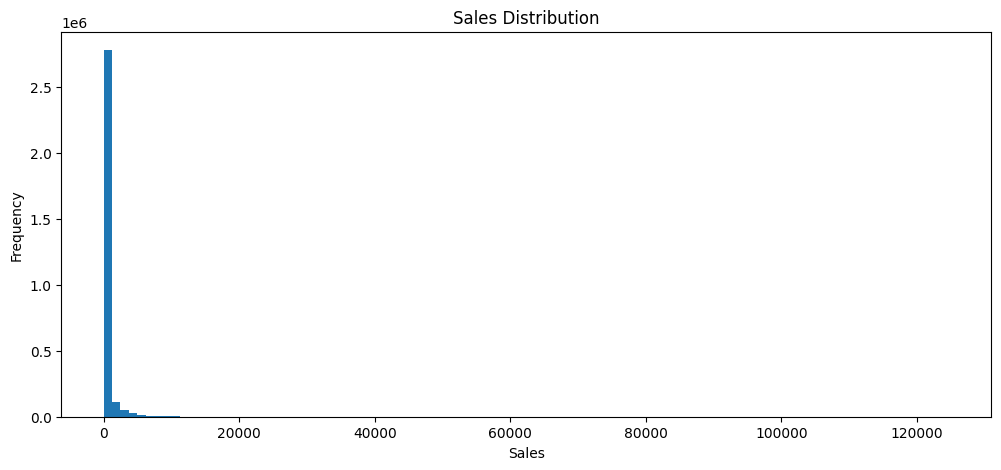

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.hist(train["sales"], bins=100)

plt.title("Sales Distribution")
plt.xlabel("Sales")
plt.ylabel("Frequency")

plt.show()

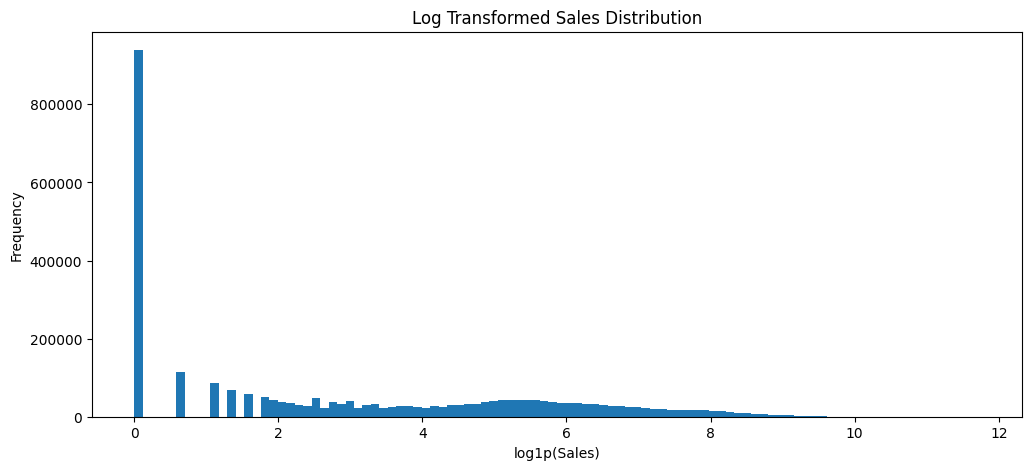

In [11]:
plt.figure(figsize=(12, 5))

plt.hist(np.log1p(train["sales"]), bins=100)

plt.title("Log Transformed Sales Distribution")
plt.xlabel("log1p(Sales)")
plt.ylabel("Frequency")

plt.show()

### Key Findings

1. **Zero Sales:** Approximately 31.29% of the training records have zero sales, indicating that zero values are a significant part of the dataset.

2. **Right-Skewed Distribution:** The original sales distribution is highly right-skewed, with most values concentrated near zero and a small number of extremely high sales values.

3. **Mean vs. Median:** The mean (357.78) is much higher than the median (11), suggesting that high sales values significantly affect the average.

4. **High Variability:** The standard deviation (1,101.99) is considerably larger than the mean, indicating substantial variation in sales across stores, product families, and dates.

5. **No Negative Values:** No negative sales values were found in the training dataset.

6. **Log Transformation:** Applying `log1p` makes the distribution easier to visualize by compressing large values while preserving zero values. However, the transformed distribution is still not normally distributed.

### Conclusion

The target variable has a highly skewed distribution, a substantial proportion of zero values, and considerable variability. These characteristics should be considered during feature engineering, model selection, and evaluation.

### **8.2 Sales Analysis by Product Family**

In this step, we analyzed sales across different product families to identify differences in sales patterns, average demand, and the proportion of zero-sales records.

In [12]:
family_stats = train.groupby("family").agg(
    Total_Sales=("sales", "sum"),
    Mean_Sales=("sales", "mean"),
    Median_Sales=("sales", "median"),
    Zero_Sales_Pct=("sales", lambda x: (x == 0).mean() * 100)
)

family_stats = family_stats.sort_values(
    by="Mean_Sales",
    ascending=False
)

display(family_stats)

,Total_Sales,Mean_Sales,Median_Sales,Zero_Sales_Pct
family,,,,
GROCERY I,3.434627e+08,3776.972100,3185.0000,8.062813
BEVERAGES,2.169545e+08,2385.793151,1784.0000,8.061714
PRODUCE,1.227047e+08,1349.352123,398.2905,28.355107
CLEANING,9.752129e+07,1072.416744,938.0000,8.061714
DAIRY,6.448771e+07,709.154889,520.0000,8.061714
BREAD/BAKERY,4.213395e+07,463.336254,401.0000,8.060614
POULTRY,3.187600e+07,350.532292,205.7430,8.076010
MEATS,3.108647e+07,341.849965,224.9365,8.061714
PERSONAL CARE,2.459205e+07,270.432513,222.0000,8.065013


### Key Findings

1. **Sales Differences:** Sales vary significantly across product families. GROCERY I has the highest average sales (3,776.97), while BOOKS has the lowest (0.07).

2. **High-Sales Families:** GROCERY I, BEVERAGES, PRODUCE, CLEANING, and DAIRY are among the highest-performing product families in terms of total and average sales.

3. **Low-Sales Families:** BOOKS, BABY CARE, and HOME APPLIANCES have very low average sales compared to other product families.

4. **Zero Sales:** The percentage of zero-sales records varies considerably across families. BOOKS has the highest percentage (96.96%), followed by BABY CARE (94.13%).

5. **Mean vs. Median:** For most product families, the mean is higher than the median, indicating right-skewed sales distributions.

6. **Different Sales Patterns:** The significant differences between product families suggest that sales behavior is not uniform across all categories.

7. **Potential Historical Effects:** Some product families have similar zero-sales percentages, around 8.06%, while others have substantially higher percentages. This pattern requires further investigation.

### Conclusion

Product families exhibit substantially different sales behaviors. These differences should be considered during feature engineering and model development. Further investigation is needed to understand the reasons behind the high proportion of zero-sales records in certain families.

### **8.3 Sales Analysis by Store**

In this step, we analyzed sales across different stores to identify differences in sales performance and understand how sales are distributed among store locations.

In [13]:
store_stats = train.groupby("store_nbr").agg(
    Total_Sales=("sales", "sum"),
    Mean_Sales=("sales", "mean"),
    Median_Sales=("sales", "median"),
    Zero_Sales_Pct=("sales", lambda x: (x == 0).mean() * 100)
)

store_stats = store_stats.sort_values(
    by="Mean_Sales",
    ascending=False
)

display(store_stats)

,Total_Sales,Mean_Sales,Median_Sales,Zero_Sales_Pct
store_nbr,,,,
44,6.208755e+07,1117.245254,75.0000,17.947887
45,5.449801e+07,980.673908,62.0000,19.358670
47,5.094831e+07,916.798209,51.0000,18.953790
3,5.048191e+07,908.405495,64.0000,18.140430
49,4.342010e+07,781.330450,48.0000,19.347873
46,4.189606e+07,753.905962,36.0000,19.320881
48,3.593313e+07,646.604950,30.0000,21.321889
51,3.291149e+07,592.231511,27.0000,20.121644
8,3.049429e+07,548.734739,39.0000,19.930900


### Key Findings

1. **Sales Differences:** Sales vary significantly across stores. Store 44 has the highest average sales (1,117.25), while Store 52 has the lowest (48.52).

2. **High-Performing Stores:** Stores 44, 45, 47, and 3 have the highest average sales among all stores.

3. **Low-Sales Stores:** Stores 52, 22, 42, and 21 have relatively low average sales compared to other stores.

4. **Zero Sales:** The percentage of zero-sales records varies considerably across stores. Store 52 has the highest percentage (93.54%), followed by Store 22 (68.55%).

5. **Median Sales:** Several stores have a median sales value of zero, indicating that at least half of their records have zero sales.

6. **Potential Store Effects:** Differences in store location, type, and cluster may help explain variations in sales performance.

### Conclusion

Sales behavior differs substantially across stores. Store-related information may provide useful features for forecasting. Stores with unusually high zero-sales percentages require further investigation before making assumptions about their sales patterns.

### **8.4 Store Metadata Analysis**

In this step, we combined store-level sales statistics with store metadata to investigate how store characteristics, including location, type, and cluster, relate to sales performance.

In [14]:
store_analysis = store_stats.merge(
    stores,
    on="store_nbr",
    how="left"
)

display(
    store_analysis.sort_values(
        by="Mean_Sales",
        ascending=False
    )
)

,store_nbr,Total_Sales,Mean_Sales,Median_Sales,Zero_Sales_Pct,city,state,type,cluster
0,44,6.208755e+07,1117.245254,75.0000,17.947887,Quito,Pichincha,A,5
1,45,5.449801e+07,980.673908,62.0000,19.358670,Quito,Pichincha,A,11
2,47,5.094831e+07,916.798209,51.0000,18.953790,Quito,Pichincha,A,14
3,3,5.048191e+07,908.405495,64.0000,18.140430,Quito,Pichincha,D,8
4,49,4.342010e+07,781.330450,48.0000,19.347873,Quito,Pichincha,A,11
5,46,4.189606e+07,753.905962,36.0000,19.320881,Quito,Pichincha,A,14
6,48,3.593313e+07,646.604950,30.0000,21.321889,Quito,Pichincha,A,14
7,51,3.291149e+07,592.231511,27.0000,20.121644,Guayaquil,Guayas,A,17
8,8,3.049429e+07,548.734739,39.0000,19.930900,Quito,Pichincha,D,8
9,50,2.865302e+07,515.601753,32.0000,20.652487,Ambato,Tungurahua,A,14


### Key Findings

1. **Store Locations:** The highest-performing stores are concentrated in Quito, particularly stores 44, 45, 47, and 3.

2. **Store Types:** High-sales stores belong to different store types, indicating that store type alone may not explain sales performance.

3. **Store Clusters:** Stores with similar sales performance may belong to different clusters, suggesting that cluster information requires further investigation.

4. **Geographical Differences:** Low-performing stores are located in different cities, including Manta, Puyo, and Cuenca.

5. **Store Characteristics:** The merged dataset provides additional features such as city, state, store type, and cluster that may help explain differences in sales.

### Conclusion

Store metadata provides potentially useful information for understanding sales variations. However, the observed patterns are preliminary and require further analysis before drawing conclusions about the relationship between store characteristics and sales.

### **8.5 Sales Analysis by Store Type**

In this step, we grouped stores by their types to investigate differences in sales performance and examine whether store classification is associated with sales patterns.

In [15]:
store_type_stats = train.merge(
    stores[["store_nbr", "type"]],
    on="store_nbr",
    how="left"
).groupby("type").agg(
    Total_Sales=("sales", "sum"),
    Mean_Sales=("sales", "mean"),
    Median_Sales=("sales", "median"),
    Zero_Sales_Pct=("sales", lambda x: (x == 0).mean() * 100),
    Number_of_Stores=("store_nbr", "nunique")
)

display(store_type_stats.sort_values(
    by="Mean_Sales",
    ascending=False
))

,Total_Sales,Mean_Sales,Median_Sales,Zero_Sales_Pct,Number_of_Stores
type,,,,,
A,3.530438e+08,705.878743,24.0,27.840559,9
D,3.510833e+08,350.979407,16.0,26.676604,18
B,1.452606e+08,326.739714,7.0,33.300493,8
E,5.982244e+07,269.121301,4.0,38.344850,4
C,1.644347e+08,197.263301,5.0,35.960436,15


### Key Findings

1. **Store Type A:** Type A has the highest average sales (705.88), significantly outperforming the other store types.

2. **Store Type D:** Type D has the second-highest average sales (350.98) and the largest number of stores (18).

3. **Store Type C:** Despite having 15 stores, Type C has the lowest average sales (197.26).

4. **Zero Sales:** Type E has the highest percentage of zero-sales records (38.34%), while Type D has the lowest (26.68%).

5. **Mean vs. Median:** The mean is considerably higher than the median across all store types, confirming the highly right-skewed nature of sales.

6. **Store Type Differences:** Sales performance varies considerably across store types, suggesting that store type may be a useful predictive feature.

### Conclusion

Store types exhibit different sales patterns. Type A has the highest average sales, while Type C has the lowest. Store type should be considered as a potential feature during model development.

### **8.6 Sales Analysis by Cluster**

In this step, we grouped stores by their cluster assignments to investigate differences in sales performance and identify potential patterns among stores belonging to the same cluster.

In [16]:
cluster_stats = store_analysis.groupby("cluster").agg(
    Total_Sales=("Total_Sales", "sum"),
    Mean_Sales=("Mean_Sales", "mean"),
    Median_Sales=("Median_Sales", "median"),
    Zero_Sales_Pct=("Zero_Sales_Pct", "mean"),
    Number_of_Stores=("store_nbr", "nunique")
)

cluster_stats = cluster_stats.sort_values(
    by="Mean_Sales",
    ascending=False
)

display(cluster_stats)

,Total_Sales,Mean_Sales,Median_Sales,Zero_Sales_Pct,Number_of_Stores
cluster,,,,,
5,6.208755e+07,1117.245254,75.0000,17.947887,1
14,1.574305e+08,708.227718,34.0000,20.062262,4
8,1.079282e+08,647.377856,39.0000,19.634588,3
11,1.006143e+08,603.507018,48.0000,44.082152,3
17,3.291149e+07,592.231511,27.0000,20.121644,1
6,1.142544e+08,342.661732,12.5000,34.736918,6
1,5.437675e+07,326.163967,18.0000,26.025696,3
12,1.803097e+07,324.461406,10.0000,30.479378,1
13,7.210225e+07,324.364108,21.1085,27.643867,4


### Key Findings

1. **Cluster Differences:** Average sales vary considerably across clusters, indicating differences in sales performance among store groups.

2. **Highest-Performing Clusters:** Clusters 5, 14, 8, and 11 have the highest average sales.

3. **Lowest-Performing Clusters:** Clusters 7, 3, and 15 have relatively low average sales.

4. **Cluster Size:** Cluster 3 contains the largest number of stores (7), while several clusters contain only one store.

5. **Zero Sales:** Cluster 7 has the highest zero-sales percentage (51.61%), followed by Cluster 11 (44.08%).

6. **Interpretation Limitations:** Clusters containing only one store cannot provide sufficient evidence about general group-level sales patterns.

### Conclusion

Sales performance differs across clusters. Cluster information may provide useful predictive features, but cluster size and differences in zero-sales percentages should be considered when interpreting these results.

## 9. Transactions Analysis

In this step, we examined transaction patterns across stores to understand customer activity and investigate its potential relationship with daily sales.

In [17]:
transaction_stats = transactions.groupby("store_nbr").agg(
    Total_Transactions=("transactions", "sum"),
    Mean_Transactions=("transactions", "mean"),
    Median_Transactions=("transactions", "median"),
    Max_Transactions=("transactions", "max")
)

display(
    transaction_stats.sort_values(
        by="Mean_Transactions",
        ascending=False
    )
)

,Total_Transactions,Mean_Transactions,Median_Transactions,Max_Transactions
store_nbr,,,,
44,7273093,4336.966607,4170.0,8359
47,6535810,3897.322600,3685.0,7727
45,6201115,3697.742993,3515.0,7305
46,5990113,3571.921884,3230.0,8001
3,5366350,3201.879475,3100.5,6085
48,5107785,3045.787120,2705.0,7044
8,4637971,2767.285800,2740.5,5261
49,4574103,2727.550984,2671.0,6600
50,4384444,2614.456768,2448.0,5456


### Key Findings

1. **Highest Transaction Activity:** Store 44 has the highest average number of daily transactions (4,336.97), followed by stores 47, 45, and 46.

2. **Sales and Transactions:** Several stores with high average sales also have high average transaction counts, suggesting a potential relationship between customer activity and sales.

3. **Store 52:** Despite having the lowest average sales (48.52), Store 52 records an average of 2,333.84 transactions, indicating that transaction volume alone does not explain sales performance.

4. **Transaction Variability:** Average transaction counts differ considerably across stores, reflecting differences in customer activity.

5. **Potential Predictive Feature:** Historical transaction counts may provide useful information for forecasting sales, but future transaction values are unavailable in the test dataset.

### Conclusion

Transaction activity varies significantly across stores and may be associated with sales performance. However, transaction volume alone does not fully explain sales differences. Further analysis is needed to investigate the relationship between daily transactions and sales.

In [18]:
daily_sales = train.groupby(
    ["date", "store_nbr"],
    as_index=False
)["sales"].sum()

sales_transactions = daily_sales.merge(
    transactions,
    on=["date", "store_nbr"],
    how="inner"
)

print("Merged Shape:", sales_transactions.shape)

print("\nCorrelation:")
print(
    sales_transactions[
        ["sales", "transactions"]
    ].corr()
)

Merged Shape: (83488, 4)

Correlation:
                 sales  transactions
sales         1.000000      0.837384
transactions  0.837384      1.000000


### Correlation Analysis

The daily sales data was aggregated at the store-date level before merging it with transaction data to ensure consistent data granularity.

### Key Findings

1. **Data Aggregation:** Sales were aggregated by date and store number because the original training dataset contains separate records for each product family.

2. **Successful Merge:** The merged dataset contains 83,488 records, matching the number of records in the transactions dataset.

3. **Positive Correlation:** A Pearson correlation coefficient of 0.837 indicates a strong positive linear relationship between daily sales and transaction counts.

4. **Sales and Customer Activity:** Stores with higher transaction counts generally tend to have higher sales.

5. **Interpretation:** Correlation does not imply causation, and transaction counts alone do not explain all variations in sales.

### Conclusion

Daily transaction counts show a strong positive association with daily sales. Historical transaction data may provide useful insights for forecasting, although actual transaction values are unavailable for the test period.

## 10. Oil Price Analysis

In this step, we examined historical oil prices, their temporal coverage, and missing values to assess their potential usefulness as external features for sales forecasting.

In [19]:
oil["date"] = pd.to_datetime(oil["date"])

print("Oil Price Statistics:")
display(oil["dcoilwtico"].describe())

print("\nMissing Oil Prices:")
print(oil["dcoilwtico"].isnull().sum())

print("\nMissing Dates:")
display(oil[oil["dcoilwtico"].isnull()][["date"]].head(10))

Oil Price Statistics:


count    1175.000000
mean       67.714366
std        25.630476
min        26.190000
25%        46.405000
50%        53.190000
75%        95.660000
max       110.620000
Name: dcoilwtico, dtype: float64


Missing Oil Prices:
43

Missing Dates:


,date
0,2013-01-01
14,2013-01-21
34,2013-02-18
63,2013-03-29
104,2013-05-27
132,2013-07-04
174,2013-09-02
237,2013-11-28
256,2013-12-25
261,2014-01-01


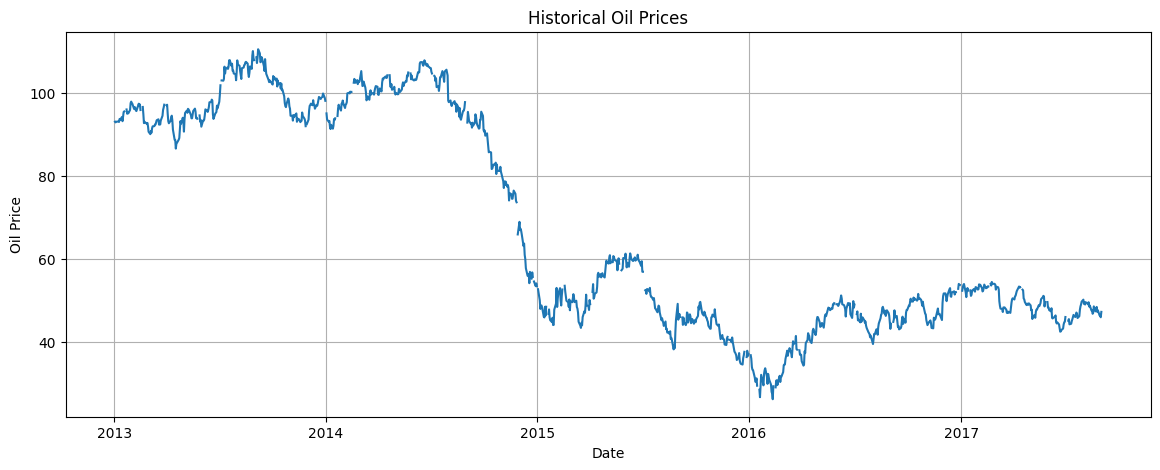

In [20]:
plt.figure(figsize=(14, 5))

plt.plot(oil["date"], oil["dcoilwtico"])

plt.title("Historical Oil Prices")
plt.xlabel("Date")
plt.ylabel("Oil Price")

plt.grid()
plt.show()

In [21]:
missing_oil = oil[oil["dcoilwtico"].isnull()].copy()

missing_oil["day_name"] = missing_oil["date"].dt.day_name()

print("Missing Values by Day:")
display(missing_oil["day_name"].value_counts())

print("\nFirst Missing Dates:")
display(missing_oil[["date", "day_name"]].head(15))

Missing Values by Day:


day_name
Monday       23
Friday        9
Thursday      7
Tuesday       2
Wednesday     2
Name: count, dtype: int64


First Missing Dates:


,date,day_name
0,2013-01-01,Tuesday
14,2013-01-21,Monday
34,2013-02-18,Monday
63,2013-03-29,Friday
104,2013-05-27,Monday
132,2013-07-04,Thursday
174,2013-09-02,Monday
237,2013-11-28,Thursday
256,2013-12-25,Wednesday
261,2014-01-01,Wednesday


In [22]:
oil = oil.sort_values("date")

oil["dcoilwtico"] = oil["dcoilwtico"].ffill().bfill()

print("Missing Values After Filling:", oil["dcoilwtico"].isnull().sum())

Missing Values After Filling: 0


### Key Findings

1. **Oil Price Range:** Oil prices ranged from approximately $26.19 to $110.62 during the observed period.

2. **Missing Values:** The dataset contains 43 missing oil prices (approximately 3.53%).

3. **Missing Dates Pattern:** Missing values occur on different weekdays, with Mondays accounting for the largest share (23 records).

4. **Price Trends:** Oil prices experienced a significant decline between 2014 and early 2016, followed by a partial recovery.

5. **Missing Value Treatment:** Missing values were handled using forward fill, with backward fill applied to the initial missing value.

### Conclusion

Oil prices represent a potentially useful external feature. Their historical trends and missing values should be considered during preprocessing and feature engineering.

## 11. Holidays Analysis

In this step, we examined holiday events to understand their distribution, categories, and potential impact on sales patterns.

In [23]:
print("Holiday Types:")
display(holidays["type"].value_counts())

print("\nHoliday Locales:")
display(holidays["locale"].value_counts())

print("\nTransferred Events:")
display(holidays["transferred"].value_counts())

Holiday Types:


type
Holiday       221
Event          56
Additional     51
Transfer       12
Bridge          5
Work Day        5
Name: count, dtype: int64


Holiday Locales:


locale
National    174
Local       152
Regional     24
Name: count, dtype: int64


Transferred Events:


transferred
False    338
True      12
Name: count, dtype: int64

In [24]:
display(
    holidays.groupby(["locale", "type"])
    .size()
    .reset_index(name="Count")
    .sort_values("Count", ascending=False)
)

,locale,type,Count
1,Local,Holiday,137
6,National,Holiday,60
5,National,Event,56
3,National,Additional,40
9,Regional,Holiday,24
0,Local,Additional,11
7,National,Transfer,8
4,National,Bridge,5
8,National,Work Day,5
2,Local,Transfer,4


### Key Findings

1. **Holiday Types:** The dataset contains 221 Holidays, 56 Events, 51 Additional events, 12 Transfers, 5 Bridge days, and 5 Work Days.

2. **Holiday Locales:** National events account for 174 records, followed by Local events (152) and Regional events (24).

3. **Transferred Events:** 12 events are marked as transferred, requiring special attention during feature engineering.

4. **Multiple Event Types:** Holiday records represent different types of events and should not all be treated as regular holidays.

5. **Geographical Impact:** Local and Regional holidays may affect specific stores depending on their locations.

### Conclusion

Holiday information may provide valuable temporal and geographical features for sales forecasting. Event types, geographical scope, and transferred dates must be handled carefully during preprocessing.

In [25]:
holiday_date_counts = holidays.groupby("date").size()

print("Dates with Multiple Events:")
display(
    holiday_date_counts[holiday_date_counts > 1]
    .sort_values(ascending=False)
    .head(10)
)

Dates with Multiple Events:


date
2014-06-25    4
2013-06-25    3
2012-06-25    3
2015-06-25    3
2016-06-25    3
2017-06-25    3
2012-12-24    2
2013-05-12    2
2012-12-31    2
2013-12-22    2
dtype: int64

In [26]:
print(
    "Dates with Multiple Events:",
    (holiday_date_counts > 1).sum()
)

Dates with Multiple Events: 31


### Multiple Events per Date

1. **Multiple Events:** The dataset contains 31 dates with more than one holiday event.

2. **Highest Event Count:** June 25, 2014 has the highest number of recorded events, with four events.

3. **Repeated Dates:** June 25 appears across multiple years, suggesting recurring events that may be relevant to sales patterns.

4. **Data Integration:** Multiple holiday records for the same date may cause row duplication when merging with the training dataset.

### Conclusion

Holiday data requires careful preprocessing before integration. Aggregating events by date and creating appropriate temporal features will help prevent unintended row duplication.


## 1. خلاصة فهم البيانات (Dataset Understanding Summary)

تعرفنا على مسابقة **Store Sales – Time Series Forecasting** وفهمنا هدفها الأساسي، وهو التنبؤ بالمبيعات اليومية لمختلف فئات المنتجات في مجموعة من المتاجر في الإكوادور.

حددنا المتغير المستهدف (`sales`)، والبيانات المتاحة، ومقياس التقييم المستخدم وهو `RMSLE`.

## 2. هيكل البيانات (Dataset Structure)

قمنا بتحميل وفحص مجموعات البيانات السبع:

- `train.csv`
- `test.csv`
- `stores.csv`
- `oil.csv`
- `holidays_events.csv`
- `transactions.csv`
- `sample_submission.csv`

تحتوي بيانات التدريب على 3,000,888 سجل، بينما تحتوي بيانات الاختبار على 28,512 سجل.

كما فحصنا أبعاد مجموعات البيانات، والأعمدة، وأنواع البيانات، والأعمدة المرشحة لتكون مفاتيح أساسية.

## 3. تحليل جودة البيانات (Data Quality Analysis)

- لم نعثر على أي صفوف مكررة بالكامل في مجموعات البيانات.
- لم نعثر على قيم مفقودة في مجموعتي التدريب والاختبار.
- تحتوي بيانات أسعار النفط على 43 قيمة مفقودة، بنسبة تقارب 3.53%.
- عالجنا القيم المفقودة في أسعار النفط باستخدام `Forward Fill` و`Backward Fill` بعد ترتيب البيانات حسب التاريخ.

## 4. تحليل المتغير المستهدف (Target Variable Analysis)

قمنا بفحص توزيع المتغير المستهدف (`sales`).

أهم النتائج:

- توزيع المبيعات منحرف بشدة نحو اليمين (Right-Skewed).
- قيمة المتوسط أعلى بكثير من الوسيط.
- يوجد 939,130 سجلًا بقيمة مبيعات تساوي صفرًا.
- لم نجد أي قيم مبيعات سالبة.
- أعلى قيمة مبيعات مسجلة هي 124,717.

كما رسمنا توزيع المبيعات قبل وبعد تطبيق التحويل اللوغاريتمي باستخدام `log1p()` لفهم التوزيع بصورة أفضل.

## 5. تحليل المبيعات حسب فئات المنتجات (Sales Patterns Across Product Families)

حللنا إحصائيات المبيعات لمختلف فئات المنتجات.

أهم النتائج:

- تحقق فئتا `GROCERY I` و`BEVERAGES` أعلى مستويات المبيعات.
- تختلف أحجام المبيعات بشكل كبير بين فئات المنتجات.
- بعض الفئات لديها نسب مرتفعة من الأيام التي لا تحقق فيها مبيعات.
- سجلت فئتا `BOOKS` و`BABY CARE` نسبًا مرتفعة جدًا من المبيعات الصفرية.

تشير هذه النتائج إلى أن فئة المنتج (`family`) من الخصائص المهمة لفهم سلوك المبيعات.

## 6. تحليل المتاجر (Store-Level Analysis)

فحصنا أداء المبيعات عبر المتاجر الـ54، ودرسنا بعض خصائصها الجغرافية والتشغيلية.

كما استكشفنا العلاقة بين المبيعات وخصائص المتاجر، ومنها:

- المدينة (`city`).
- الولاية أو المنطقة (`state`).
- نوع المتجر (`type`).
- المجموعة (`cluster`).

أظهرت النتائج وجود اختلافات واضحة في أداء المبيعات ونسب المبيعات الصفرية بين المتاجر.

## 7. تحليل المعاملات (Transactions Analysis)

درسنا أنماط المعاملات اليومية عبر المتاجر.

قمنا بتجميع المبيعات اليومية باستخدام `date` و`store_nbr`، ثم دمجنا النتائج مع بيانات المعاملات.

بلغ معامل الارتباط بين المبيعات اليومية وعدد المعاملات حوالي **0.837**.

يشير ذلك إلى وجود علاقة إيجابية قوية بين عدد معاملات العملاء وحجم المبيعات.

وبالتالي، قد تكون بيانات `transactions` مفيدة في بناء النموذج، بشرط التأكد من توفرها خلال فترة التنبؤ.

## 8. تحليل أسعار النفط (Oil Prices Analysis)

فحصنا أسعار النفط التاريخية باستخدام المتغير `dcoilwtico`.

أهم النتائج:

- تراوحت أسعار النفط تقريبًا بين 26.19 و110.62.
- تحتوي البيانات على 43 قيمة مفقودة.
- شهدت أسعار النفط انخفاضًا ملحوظًا بين عام 2014 وبداية عام 2016، تلاه تعافٍ جزئي.
- عالجنا القيم المفقودة باستخدام `Forward Fill` و`Backward Fill`.

قد تمثل أسعار النفط متغيرًا خارجيًا مفيدًا لالتقاط بعض التغيرات الاقتصادية العامة.

## 9. تحليل العطلات والأحداث (Holidays Analysis)

فحصنا بيانات العطلات والأحداث لفهم توزيعها وتصنيفاتها وتأثيرها المحتمل على أنماط المبيعات.

أهم النتائج:

- تحتوي البيانات على 350 سجلًا تمثل 312 تاريخًا فريدًا.
- يوجد 31 تاريخًا يحتوي على أكثر من حدث واحد.
- تصنف الأحداث إلى `National` و`Local` و`Regional`.
- تتضمن أنواع الأحداث `Holiday` و`Event` و`Additional` و`Transfer` و`Bridge` و`Work Day`.
- بعض العطلات يتم نقلها إلى تواريخ أخرى.

**ملاحظة مهمة لمرحلة Preprocessing:**

إن دمج بيانات العطلات مباشرة مع بيانات المبيعات باستخدام `date` قد يؤدي إلى تكرار سجلات المبيعات؛ لأن التاريخ الواحد قد يحتوي على أكثر من حدث.

لذلك، يجب معالجة بيانات العطلات قبل الدمج، مثل تجميع الأحداث حسب التاريخ أو تحويلها إلى Features مناسبة.

كذلك، يجب مراعاة المواقع الجغرافية للمتاجر عند التعامل مع العطلات المحلية والإقليمية، لأنها لا تؤثر بالضرورة على جميع المتاجر.

أما العطلات المنقولة (`transferred = True`)، فيجب التعامل معها بحذر؛ فالتاريخ الأصلي يُعامل غالبًا كيوم عادي، ويجب تحديد تاريخ الاحتفال الفعلي من خلال الحدث المقابل من نوع `Transfer`.

---

# الخلاصة العامة والاعتبارات المستقبلية (General Findings & Future Considerations)

ساعدنا اليوم الأول على فهم هيكل البيانات، وتوزيع المتغير المستهدف، وجودة البيانات، والعلاقات الأولية بين مجموعات البيانات المختلفة.

كما حددنا مجموعة من النقاط المهمة التي سنحتاج إلى دراستها في المراحل القادمة.

### 1. المعالجة المسبقة وهندسة الخصائص (Preprocessing & Feature Engineering)

سنحتاج إلى دراسة ومعالجة الأمور التالية:

- **العروض الترويجية (Promotion Analysis):** فحص توزيع `onpromotion` وفهم علاقته بالمبيعات.
- **الخصائص الزمنية (Temporal Features):** استخراج خصائص مثل `Day of Week` و`Month` ودراسة الأنماط الموسمية (`Seasonality`).
- **خصائص العطلات (Holiday Features):** معالجة بيانات العطلات بصورة صحيحة قبل دمجها مع بيانات المبيعات، لتجنب تكرار السجلات أو إسناد الأحداث إلى تواريخ غير صحيحة.
- **القيم المفقودة (Missing Values):** دراسة الاستراتيجيات المناسبة لمعالجة القيم المفقودة في مجموعات البيانات الإضافية.

### 2. استراتيجية التحقق ومنع تسرب البيانات (Validation Strategy & Data Leakage)

بما أن المسألة تتعلق بالتنبؤ بالسلاسل الزمنية، فإن استخدام تقسيم عشوائي للبيانات (`Random Train-Validation Split`) قد يؤدي إلى نتائج مضللة.

يجب تصميم استراتيجية تحقق تراعي الترتيب الزمني للبيانات، وتمنع تسرب المعلومات المستقبلية إلى بيانات التدريب.

كما يجب التأكد من أن جميع الخصائص المستخدمة أثناء التحقق ستكون متاحة بالفعل عند تنفيذ التنبؤ.

### 3. الخصائص الإضافية (Additional Features)

قد توفر مجموعات البيانات التالية معلومات مفيدة لتحسين التنبؤ:

- خصائص المتاجر.
- أسعار النفط.
- المعاملات اليومية.
- العطلات والأحداث.
- الأنشطة الترويجية.

لكن يجب تقييم فائدة هذه الخصائص من خلال استراتيجية تحقق سليمة، وليس بناءً على الافتراضات فقط.

### الخاتمة (Conclusion)

كشف التحليل الأولي عن اختلافات واضحة في سلوك المبيعات بين فئات المنتجات والمتاجر والفترات الزمنية.

كما أظهر أهمية دراسة الأنماط الزمنية، والعروض الترويجية، والمعاملات، وأسعار النفط، والعطلات والأحداث.

ستركز المرحلة القادمة على المعالجة المسبقة للبيانات، وهندسة الخصائص الزمنية، وتصميم استراتيجية تحقق موثوقة قبل البدء في تطوير النماذج التنبؤية.

---

## 1. Dataset Understanding Summary

We explored the Store Sales – Time Series Forecasting competition and understood its main objective: predicting daily sales for different product families across multiple stores in Ecuador.

We identified the target variable (`sales`), the available datasets, and the evaluation metric, `RMSLE`.

## 2. Dataset Structure

We loaded and examined all seven datasets:

- `train.csv`
- `test.csv`
- `stores.csv`
- `oil.csv`
- `holidays_events.csv`
- `transactions.csv`
- `sample_submission.csv`

The training dataset contains 3,000,888 records, while the test dataset contains 28,512 records.

We also examined dataset dimensions, columns, data types, and potential key columns.

## 3. Data Quality Analysis

- No completely duplicated rows were found in any dataset.
- No missing values were found in the training or test datasets.
- The oil dataset contains 43 missing values (approximately 3.53%).
- Missing oil prices were handled using forward fill and backward fill after sorting the data by date.

## 4. Target Variable Analysis

We examined the distribution of the target variable (`sales`).

Key observations:

- Sales are highly right-skewed.
- The mean is significantly higher than the median.
- Approximately 939,130 records have zero sales.
- No negative sales values were found.
- The maximum recorded sales value is 124,717.

We also visualized the original and log-transformed sales distributions using `log1p()` to better understand the target distribution.

## 5. Sales Patterns Across Product Families

We analyzed sales statistics across different product families.

Key observations:

- `GROCERY I` and `BEVERAGES` have the highest sales volumes.
- Sales volumes vary considerably across product families.
- Some product families have very high percentages of zero-sales records.
- `BOOKS` and `BABY CARE` have particularly high zero-sales percentages.

These findings indicate that product family (`family`) is an important feature for understanding sales behavior.

## 6. Store-Level Analysis

We examined sales performance across the 54 stores and investigated their geographical and operational characteristics.

We also explored relationships between sales and store attributes, including:

- City.
- State.
- Store type.
- Cluster.

The results revealed considerable differences in sales performance and zero-sales percentages across stores.

## 7. Transactions Analysis

We investigated transaction patterns across stores.

We aggregated daily sales using `date` and `store_nbr`, then merged the results with the transactions dataset.

The resulting correlation between daily sales and transactions was approximately **0.837**.

This indicates a strong positive relationship between customer transaction volume and sales.

Therefore, transactions may be a useful feature, provided they are available during the prediction period.

## 8. Oil Prices Analysis

We examined historical oil prices represented by the `dcoilwtico` variable.

Key observations:

- Oil prices ranged approximately from 26.19 to 110.62.
- The dataset contains 43 missing values.
- Oil prices experienced a significant decline between 2014 and early 2016, followed by a partial recovery.
- Missing values were handled using forward fill and backward fill.

Oil prices may represent a useful external feature for capturing broader economic conditions.

## 9. Holidays Analysis

We examined holiday events to understand their distribution, categories, and potential impact on sales patterns.

Key observations:

- The dataset contains 350 event records representing 312 unique dates.
- There are 31 dates with multiple events.
- Events are classified into National, Local, and Regional categories.
- Event types include `Holiday`, `Event`, `Additional`, `Transfer`, `Bridge`, and `Work Day`.
- Some holidays are transferred to different dates.

**Important consideration for preprocessing:**

Directly merging the holidays dataset with sales data using `date` may duplicate sales records because multiple events can occur on the same date.

Therefore, holiday events should be processed before merging, for example, by aggregating events by date or transforming them into appropriate features.

Local and regional holidays should also be matched with the corresponding store locations, as they do not necessarily affect all stores.

Transferred holidays (`transferred = True`) require special handling. The original date should generally be treated as a normal day, while the actual celebration date should be identified through the corresponding `Transfer` event.

---

# General Findings & Future Considerations

Day 1 helped us understand the dataset structure, target distribution, data quality, and initial relationships between the available datasets.

Several important considerations were identified for the next stages.

### 1. Preprocessing & Feature Engineering

We will need to investigate and handle the following:

- **Promotion Analysis:** Examine the distribution of `onpromotion` and understand its relationship with sales.
- **Temporal Features:** Extract features such as `Day of Week` and `Month`, and investigate seasonal patterns (`Seasonality`).
- **Holiday Features:** Properly process holiday events before merging them with sales data to avoid duplicated records or incorrect event assignments.
- **Missing Values:** Investigate appropriate strategies for handling missing values in additional datasets.

### 2. Validation Strategy & Data Leakage

Since this is a time-series forecasting problem, a random train-validation split may produce misleading results.

We must develop a time-aware validation strategy that respects chronological order and prevents future information from leaking into the training process.

We must also verify that all features used during validation would realistically be available at prediction time.

### 3. Additional Features

The following datasets may provide useful information for improving predictions:

- Store characteristics.
- Oil prices.
- Daily transactions.
- Holiday events.
- Promotional activities.

However, their usefulness must be evaluated through a reliable validation strategy rather than assumptions.

### Conclusion

The initial analysis revealed considerable differences in sales behavior across product families, stores, and time periods.

It also highlighted the importance of investigating temporal patterns, promotional activities, transactions, oil prices, and holiday events.

The next stage will focus on data preprocessing, temporal feature engineering, and designing a reliable validation strategy before developing predictive models.